# Clasificación Automática de Estadios del Sueño — Ensamble Universal SOTA (CRNN V7 + Data Augmentation + Optuna)

Este cuaderno implementa la arquitectura definitiva de **Generalización de Dominio** para la clasificación multiclase del sueño sobre la base de datos *Sleep-EDF Expanded* (`Sleep-Telemetry` + `Sleep-Cassette`).

**Innovaciones Metodológicas de esta Versión (V7):**
1. **Entrenamiento Multimuestral Unificado:** Fusión controlada de cohortes clínicas (*Telemetry*) y sanas (*Cassette*) desde la etapa de extracción de características, reservando una bóveda *Hold-Out* estricta de 20 registros inéditos.
2. **Blindaje contra *Data Leakage*:** Asignación de prefijos de cohorte (`ST_` y `SC_`) para evitar colisión de sujetos y partición interna mediante `GroupShuffleSplit` agrupado por paciente.
3. **Data Augmentation Dinámico en GPU:** Integración de capas `GaussianNoise` y `SpatialDropout1D` activas exclusivamente durante el entrenamiento para lograr agnosticidad frente al hardware de captura.
4. **Embeddings *Out-Of-Fold* (OOF) y Optimización Bayesiana (Optuna):** Entrenamiento del clasificador *LightGBM* sobre representaciones latentes extraídas fuera de muestra (evitando el *In-Sample Stacking Leakage*) y búsqueda automatizada de hiperparámetros con **Optuna**.

## 1. Entorno, Hiperparámetros Globales y Configuración de MLflow
Inicialización del entorno en GPU con precisión mixta (`mixed_float16`), instalación de dependencias (MNE, MLflow, Optuna) y definición de constantes fisiológicas bajo el estándar de la AASM (5 estadios).

In [1]:
!pip install --upgrade mne mlflow optuna -q

import os
import re
import gc
import math
import warnings
import joblib
from pathlib import Path

import numpy as np
import pandas as pd
import mne
import mlflow
import optuna
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import mixed_precision
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, cohen_kappa_score
import lightgbm as lgb

# Configuración de entorno y aceleración por hardware (A100)
mixed_precision.set_global_policy('mixed_float16')
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"  # Evita el bloqueo de MLflow 3.x en Drive
mne.set_log_level("ERROR")
tf.get_logger().setLevel("ERROR")
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")

# Montar Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# --- CONSTANTES DE RUTA Y SEÑAL ---
BASE_TELEMETRY = Path("/content/drive/MyDrive/Bimestre 7/Proyectos/sleep-telemetry")
BASE_CASSETTE  = Path("/content/drive/MyDrive/Bimestre 7/Proyectos/sleep-cassette")

L_FREQ, H_FREQ = 0.3, 35.0    # Filtrado pasabanda estándar clínico (Hz)
EPOCA_SEG = 30.0              # Ventana estándar AASM (segundos)
FUNDIR_N3_N4 = True           # Estándar AASM: N3 y N4 se unifican en sueño profundo (N3)
RECORTAR_W_MIN = 30           # Recorte de vigilia excesiva pre y post sueño

# --- HIPERPARÁMETROS DE LA ARQUITECTURA V7 ---
N_SPLITS = 5                  # GroupKFold de 5 pliegues (Balance óptimo RAM / Rigor estadístico)
SEQ_LEN = 15                  # Contexto bidireccional de 21 épocas (10.5 minutos)
EPOCHS_MAX = 35               # Tope de épocas por fold (controlado por EarlyStopping)
EPOCHS_MAESTRO = 20           # Épocas consolidadas para el extractor maestro
BATCH_SIZE = 128              # Tamaño de lote optimizado para GPU A100
LEARNING_RATE = 0.001

MAPA_ETAPAS = {
    "Sleep stage W": "W",
    "Sleep stage 1": "N1",
    "Sleep stage 2": "N2",
    "Sleep stage 3": "N3",
    "Sleep stage 4": "N4",
    "Sleep stage R": "REM",
}
ETAPAS_VALIDAS = ["W", "N1", "N2", "N3", "REM"] if FUNDIR_N3_N4 else ["W", "N1", "N2", "N3", "N4", "REM"]

print(f"\n✅ Entorno V7 inicializado. {len(ETAPAS_VALIDAS)} etapas AASM configuradas: {ETAPAS_VALIDAS}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.
Mounted at /content/drive

✅ Entorno V7 inicializado. 5 etapas AASM configuradas: ['W', 'N1', 'N2', 'N3', 'REM']


## 2. Pipeline de Preprocesamiento *Stateless* e Ingesta Dual sin Fuga de Datos

Este módulo implementa una tubería analógica **sin estado (*stateless*)** diseñada para ser reutilizada de forma idéntica por el microservicio en **FastAPI** durante la puesta en producción:
1. **Filtro FIR de Fase Cero (0.3 – 35.0 Hz):** Implementado con ventana de Hamming para eliminar derivas de línea base y ruido eléctrico sin introducir distorsión de fase, preservando la morfología de los husos de sueño y complejos K.
2. **Imputación Resiliente (*Zero Imputation*):** Ante la desconexión o ausencia de un canal físico en el archivo `.edf`, se inyecta un vector de ceros para mantener la geometría del tensor `(3000, 4)` y permitir que la red redistribuya la atención hacia los canales activos.
3. **Normalización Z-Score Autónoma (Época a Época):** Cada segmento de 30 segundos se estandariza con su propia media y desviación estándar ($\mu=0, \sigma=1$), permitiendo realizar inferencias en tiempo real sin depender del historial de toda la noche.
4. **Blindaje de Identificadores y Bóveda *Hold-Out*:** Se asignan prefijos únicos por cohorte (`ST_` para *Telemetry* y `SC_` para *Cassette*) para impedir colisiones de `sujeto_id`. Se fusionan las 44 noches clínicas con 40 noches sanas para el entrenamiento universal, aislando estrictamente 20 noches adicionales de *Cassette* (`[40:60]`) como bóveda de prueba final.

In [2]:
CANALES_ESPERADOS = ["EEG Fpz-Cz", "EEG Pz-Oz", "EOG horizontal", "EMG submental"]
RE_ST = re.compile(r"^ST7(\d{2})(\d)J0-PSG\.edf$", re.IGNORECASE)
RE_SC = re.compile(r"^SC4(\d{2})(\d)[A-Za-z0-9]*-PSG\.edf$", re.IGNORECASE)

def descubrir_registros_telemetry(base=BASE_TELEMETRY):
    base = Path(base)
    registros = []
    for psg in sorted(base.glob("*-PSG.edf")):
        m = RE_ST.match(psg.name)
        if m is None: continue
        ss, noche = m.group(1), m.group(2)
        candidatos = sorted(base.glob(f"ST7{ss}{noche}J?-Hypnogram.edf"))
        if not candidatos: continue
        registros.append({
            "psg": psg,
            "hyp": candidatos[0],
            "registro_id": f"ST7{ss}{noche}",
            "sujeto_id": f"ST_S{ss}",  # <-- Prefijo ST_ evita colisión con Cassette
            "cohorte": "Telemetry",
            "noche": int(noche),
        })
    return registros

def descubrir_registros_cassette(base=BASE_CASSETTE):
    base = Path(base)
    registros = []
    for psg in sorted(base.glob("*-PSG.edf")):
        m = RE_SC.match(psg.name)
        if m is None: continue
        ss, noche = m.group(1), m.group(2)
        candidatos = sorted(base.glob(f"SC4{ss}{noche}*-Hypnogram.edf"))
        if not candidatos: continue
        registros.append({
            "psg": psg,
            "hyp": candidatos[0],
            "registro_id": f"SC4{ss}{noche}",
            "sujeto_id": f"SC_S{ss}",  # <-- Prefijo SC_ evita colisión con Telemetry
            "cohorte": "Cassette",
            "noche": int(noche),
        })
    return registros

def cargar_registro_seguro(psg_file, hyp_file):
    raw = mne.io.read_raw_edf(psg_file, preload=True, verbose="ERROR")
    fs = raw.info["sfreq"]
    n_times = raw.n_times

    canales_presentes = [c for c in CANALES_ESPERADOS if c in raw.ch_names]
    if canales_presentes:
        raw.pick(canales_presentes)
        # Filtro FIR pasabanda de fase cero (ventana Hamming por defecto en MNE)
        raw.filter(l_freq=L_FREQ, h_freq=H_FREQ, verbose=False)

    datos_extraidos = []
    for canal in CANALES_ESPERADOS:
        if canal in raw.ch_names:
            idx = raw.ch_names.index(canal)
            datos_extraidos.append(raw.get_data()[idx, :] * 1e6)
        else:
            print(f"  ⚠️ {canal} ausente en {psg_file.name}. Aplicando Zero Imputation.")
            datos_extraidos.append(np.zeros(n_times))

    datos_completos = np.vstack(datos_extraidos)
    ann = mne.read_annotations(hyp_file)
    return datos_completos, ann, fs

def etiquetas_por_epoca(ann, n_epocas, epoca_seg=EPOCA_SEG):
    etiquetas = np.full(n_epocas, None, dtype=object)
    for onset, dur, desc in zip(ann.onset, ann.duration, ann.description):
        etapa = MAPA_ETAPAS.get(str(desc).strip())
        if not etapa: continue
        if FUNDIR_N3_N4 and etapa == "N4": etapa = "N3"
        i_ini = max(0, int(np.floor(onset / epoca_seg)))
        i_fin = min(n_epocas, int(np.ceil((onset + dur) / epoca_seg)))
        etiquetas[i_ini:i_fin] = etapa
    return etiquetas

def segmentar(datos, fs, epoca_seg=EPOCA_SEG):
    n_canales, n_total = datos.shape
    muestras_epoca = int(round(epoca_seg * fs))
    n_epocas = n_total // muestras_epoca
    datos = datos[:, :n_epocas * muestras_epoca]
    epocas = datos.reshape(n_canales, n_epocas, muestras_epoca)
    return np.transpose(epocas, (1, 0, 2))

def indices_recorte(y, minutos=RECORTAR_W_MIN, epoca_seg=EPOCA_SEG):
    if minutos is None: return 0, len(y)
    n_margen = int(minutos * 60 / epoca_seg)
    es_sueno = np.array([e in ("N1", "N2", "N3", "REM") for e in y])
    if not es_sueno.any(): return 0, len(y)
    primero = int(np.argmax(es_sueno))
    ultimo = len(y) - 1 - int(np.argmax(es_sueno[::-1]))
    return max(0, primero - n_margen), min(len(y), ultimo + 1 + n_margen)

def procesar_registro_cnn(reg):
    datos_completos, ann, fs = cargar_registro_seguro(reg["psg"], reg["hyp"])
    epocas_data = segmentar(datos_completos, fs)
    y = etiquetas_por_epoca(ann, n_epocas=epocas_data.shape[0])

    i0, i1 = indices_recorte(y)
    epocas_data = epocas_data[i0:i1]
    y = y[i0:i1]

    valido = np.array([e in ETAPAS_VALIDAS for e in y])
    epocas_data = epocas_data[valido]
    y = y[valido]

    # Normalización Z-Score local época a época (Stateless)
    media = np.mean(epocas_data, axis=2, keepdims=True)
    desviacion = np.std(epocas_data, axis=2, keepdims=True) + 1e-8
    epocas_data = (epocas_data - media) / desviacion

    X_cnn = np.transpose(epocas_data, (0, 2, 1))
    label_map = {stage: i for i, stage in enumerate(ETAPAS_VALIDAS)}
    y_cnn = tf.keras.utils.to_categorical([label_map[stage] for stage in y], num_classes=len(ETAPAS_VALIDAS))

    meta = pd.DataFrame({
        "sujeto_id": reg["sujeto_id"],
        "registro_id": reg["registro_id"],
        "cohorte": reg["cohorte"],
        "noche": reg["noche"],
    }, index=range(len(y)))

    return X_cnn, y_cnn, meta

def construir_dataset_cnn(registros):
    Xs, ys, ms = [], [], []
    for reg in registros:
        X, y, m = procesar_registro_cnn(reg)
        Xs.append(X)
        ys.append(y)
        ms.append(m)
    X_final = np.concatenate(Xs, axis=0).astype(np.float32)
    y_final = np.concatenate(ys, axis=0).astype(np.float32)
    meta_final = pd.concat(ms, ignore_index=True)
    return X_final, y_final, meta_final

# --- EJECUCIÓN DE LA INGESTA DUAL Y AISLAMIENTO DEL HOLD-OUT ---
print("🔍 Escaneando cohortes en disco...")
registros_tel = descubrir_registros_telemetry()
registros_cas = descubrir_registros_cassette()

# 1. Dataset de Entrenamiento Universal: 44 noches Telemetry + 40 noches Cassette
registros_train_univ = registros_tel + registros_cas[:40]

# 2. Bóveda Hold-Out Estricta: 20 noches inéditas de Cassette (Índices 40 al 60)
registros_holdout_cas = registros_cas[40:60]

print(f"  -> Noches Clínicas (Telemetry) para Entrenamiento: {len(registros_tel)}")
print(f"  -> Noches Sanas (Cassette) para Entrenamiento:     {len(registros_cas[:40])}")
print(f"  -> Total Noches Entrenamiento Universal:           {len(registros_train_univ)}")
print(f"  🔒 Bóveda Hold-Out aislada (Cassette inéditos):     {len(registros_holdout_cas)} noches")

print("\n⏳ Construyendo Tensor Universal de Entrenamiento...")
X_univ, y_univ, meta_univ = construir_dataset_cnn(registros_train_univ)

print(f"\n✅ Tensor Universal generado con éxito:")
print(f"   Geometría X_univ: {X_univ.shape} (Épocas, Muestras, Canales)")
print(f"   Pacientes únicos en Entrenamiento: {meta_univ['sujeto_id'].nunique()}")

🔍 Escaneando cohortes en disco...
  -> Noches Clínicas (Telemetry) para Entrenamiento: 44
  -> Noches Sanas (Cassette) para Entrenamiento:     40
  -> Total Noches Entrenamiento Universal:           84
  🔒 Bóveda Hold-Out aislada (Cassette inéditos):     20 noches

⏳ Construyendo Tensor Universal de Entrenamiento...

✅ Tensor Universal generado con éxito:
   Geometría X_univ: (85796, 3000, 4) (Épocas, Muestras, Canales)
   Pacientes únicos en Entrenamiento: 43


In [3]:
suj_tr_cas = {r["sujeto_id"] for r in registros_cas[:40]}
suj_ho_cas = {r["sujeto_id"] for r in registros_cas[40:60]}
cruce = suj_tr_cas & suj_ho_cas

print(f"Sujetos únicos Cassette Train: {len(suj_tr_cas)}")
print(f"Sujetos únicos Cassette Hold-Out: {len(suj_ho_cas)}")
print(f"Cruce (fuga de sujeto): {cruce}")

Sujetos únicos Cassette Train: 21
Sujetos únicos Cassette Hold-Out: 11
Cruce (fuga de sujeto): {'SC_S20'}


## 3. Arquitectura CRNN Multirrama V7 (Fusión Tardía + *Data Augmentation* en GPU)

Se evoluciona la arquitectura de **Fusión Tardía** incorporando mecanismos de regularización estocástica y aumento de datos directamente en el grafo de la GPU:
* **Inyección de Ruido Gaussiano (`GaussianNoise(0.15)`):** Perturba dinámicamente las ondas estandarizadas durante el entrenamiento para destruir el *Shortcut Learning* asociado a la impedancia de los electrodos o al amplificador físico de cada hospital.
* **Apagado Espacial de Mapas (`SpatialDropout1D(0.20)`):** Desactiva aleatoriamente canales latentes completos dentro de cada rama convolucional, forzando al módulo de **Atención Espacial** y a la red **BiLSTM** a construir representaciones redundantes y robustas.
* **Activación Inteligente:** Por diseño nativo de Keras, las capas de aumento operan exclusivamente con `training=True` (`model.fit`) y se desactivan automáticamente durante la extracción de *embeddings* e inferencia clínica (`model.predict`), garantizando cero contaminación en validación.

In [ ]:
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, Dropout, SpatialDropout1D, GaussianNoise,
    BatchNormalization, GlobalAveragePooling1D, TimeDistributed,
    Bidirectional, LSTM, Dense, Concatenate, Multiply
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

def categorical_focal_loss(gamma=2.0):
    def loss(y_true, y_pred):
        y_pred = tf.cast(y_pred, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        return -tf.reduce_sum(y_true * tf.math.pow(1.0 - y_pred, gamma) * tf.math.log(y_pred), axis=-1)
    return loss

def create_crnn_universal_v7(seq_len=SEQ_LEN, num_classes=len(ETAPAS_VALIDAS), lr=LEARNING_RATE):
    # A. Entradas Multimodales Sincronizadas
    seq_eeg = Input(shape=(seq_len, 3000, 2), name='seq_eeg')
    seq_eog = Input(shape=(seq_len, 3000, 1), name='seq_eog')
    seq_emg = Input(shape=(seq_len, 3000, 1), name='seq_emg')

    # --- CAPA DE DATA AUGMENTATION EN GPU (Solo activa en training=True) ---
    aug_eeg = GaussianNoise(0.15, name='aug_noise_eeg')(seq_eeg)
    aug_eog = GaussianNoise(0.15, name='aug_noise_eog')(seq_eog)
    aug_emg = GaussianNoise(0.15, name='aug_noise_emg')(seq_emg)

    # B. Rama Cortical (EEG) + SpatialDropout1D
    x_eeg = TimeDistributed(Conv1D(64, 10, activation='relu', padding='same'))(aug_eeg)
    x_eeg = TimeDistributed(BatchNormalization())(x_eeg)
    x_eeg = TimeDistributed(MaxPooling1D(8))(x_eeg)
    x_eeg = TimeDistributed(SpatialDropout1D(0.2))(x_eeg)
    x_eeg = TimeDistributed(Conv1D(128, 8, activation='relu', padding='same'))(x_eeg)
    x_eeg = TimeDistributed(BatchNormalization())(x_eeg)
    x_eeg = TimeDistributed(MaxPooling1D(4))(x_eeg)
    x_eeg = TimeDistributed(Dropout(0.3))(x_eeg)
    x_eeg = TimeDistributed(GlobalAveragePooling1D())(x_eeg)

    # C. Rama Ocular (EOG) + SpatialDropout1D
    x_eog = TimeDistributed(Conv1D(32, 10, activation='relu', padding='same'))(aug_eog)
    x_eog = TimeDistributed(BatchNormalization())(x_eog)
    x_eog = TimeDistributed(MaxPooling1D(8))(x_eog)
    x_eog = TimeDistributed(SpatialDropout1D(0.2))(x_eog)
    x_eog = TimeDistributed(GlobalAveragePooling1D())(x_eog)

    # D. Rama Muscular (EMG) + SpatialDropout1D
    x_emg = TimeDistributed(Conv1D(32, 10, activation='relu', padding='same'))(aug_emg)
    x_emg = TimeDistributed(BatchNormalization())(x_emg)
    x_emg = TimeDistributed(MaxPooling1D(8))(x_emg)
    x_emg = TimeDistributed(SpatialDropout1D(0.2))(x_emg)
    x_emg = TimeDistributed(GlobalAveragePooling1D())(x_emg)

    # E. Fusión Tardía y Mecanismo de Atención Espacial
    secuencia_features = Concatenate(axis=-1, name='late_fusion_concat')([x_eeg, x_eog, x_emg])
    atencion = TimeDistributed(Dense(secuencia_features.shape[-1] // 2, activation='relu'))(secuencia_features)
    atencion = TimeDistributed(Dense(secuencia_features.shape[-1], activation='sigmoid'))(atencion)
    secuencia_fusionada = Multiply(name='spatial_attention_gate')([secuencia_features, atencion])

    # F. Modelado Secuencial (BiLSTM) y Cuello de Botella Latente (64D)
    x = Bidirectional(LSTM(64, return_sequences=False), name='bilstm_context')(secuencia_fusionada)
    x = Dropout(0.4)(x)
    # VOLVEMOS A LA BASE DE 64 DIMENSIONES
    embeddings_64d = Dense(64, activation='relu', name='embeddings_latentes_64d')(x)

    # G. Capa de Clasificación Primaria
    output_layer = Dense(num_classes, activation='softmax', dtype='float32', name='softmax_clasificador')(embeddings_64d)

    model = Model(inputs=[seq_eeg, seq_eog, seq_emg], outputs=output_layer, name="CRNN_Universal_V7_Aug_SEQ21")
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss=categorical_focal_loss(gamma=1.5),
        metrics=['accuracy']
    )
    return model

## 4. Generador Nativo Multihilo con Aislamiento de Fronteras (`MultimodalDataGenerator`)

Se perfecciona el generador secuencial de Keras 3 para construir ventanas deslizantes de 15 épocas (7.5 minutos) en tiempo real sin desbordar la memoria RAM. Además, se incorpora un control de bordes por `registro_id`: si una ventana de 15 épocas intenta cruzar la frontera entre el final de la noche del Paciente A y el inicio de la noche del Paciente B, el generador rellena los extremos repitiendo la época límite del mismo paciente (`edge padding` local), erradicando cualquier contaminación cruzada entre registros.

In [ ]:
class MultimodalDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, indices, X_flat, y_flat, registro_ids, seq_len=SEQ_LEN, batch_size=BATCH_SIZE, shuffle=False, **kwargs):
        super().__init__(workers=4, use_multiprocessing=False, **kwargs)
        self.indices = np.array(indices)
        self.X_flat = X_flat
        self.y_flat = y_flat
        self.registro_ids = registro_ids
        self.seq_len = seq_len
        self.pad = seq_len // 2
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.n_total = len(X_flat)
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return math.ceil(len(self.indices) / self.batch_size)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        lote_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        X_batch = np.empty((len(lote_idx), self.seq_len, 3000, 4), dtype=np.float32)

        for i, center_idx in enumerate(lote_idx):
            reg_actual = self.registro_ids[center_idx]
            for w in range(self.seq_len):
                target_idx = center_idx - self.pad + w
                # Verificar que el índice no se salga de la matriz ni cruce a otro paciente/noche
                if target_idx < 0 or target_idx >= self.n_total or self.registro_ids[target_idx] != reg_actual:
                    X_batch[i, w] = self.X_flat[center_idx]  # Padding seguro con la época del propio paciente
                else:
                    X_batch[i, w] = self.X_flat[target_idx]

        X_eeg = X_batch[:, :, :, 0:2]
        X_eog = X_batch[:, :, :, 2:3]
        X_emg = X_batch[:, :, :, 3:4]
        y_batch = self.y_flat[lote_idx]

        return {'seq_eeg': X_eeg, 'seq_eog': X_eog, 'seq_emg': X_emg}, y_batch

## 5. Motor de Validación Cruzada (`GroupKFold`) y Extracción de Embeddings *Out-Of-Fold* (OOF)

Para entrenar el clasificador **LightGBM** de la Etapa 2 sin caer en el sesgo de memorización entre etapas (*In-Sample Stacking Leakage*), este módulo ejecuta una estrategia de **Predicción Fuera de Muestra (*Out-Of-Fold*)**:
1. Se divide el conjunto de entrenamiento universal en **5 Folds agrupados por `sujeto_id`**.
2. Dentro de cada Fold, la partición entre entrenamiento (`i_train`) y validación temprana (`i_val` para `EarlyStopping`) se realiza mediante `GroupShuffleSplit` por sujeto, evitando que ventanas solapadas del mismo paciente filtren información al `val_loss`.
3. Una vez entrenado el Fold $k$, la red se trunca en la capa `embeddings_latentes_64d` y extrae los vectores de 64 dimensiones **únicamente para el 20% de pacientes del conjunto de prueba (`i_te`) que esa red jamás vio**.
4. Al completar los 5 Folds, se obtiene la matriz completa `X_oof_embeddings` (100% fuera de muestra), la cual representa con fidelidad clínica real cómo se comportan los *embeddings* ante cerebros desconocidos.

In [ ]:
# ====================================================================
# SECCIÓN 5: VALIDACIÓN CRUZADA OOF Y REGISTRO EN MLFLOW (PRUEBA 1A)
# ====================================================================
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def entrenar_cv_y_extraer_oof(X_flat, y_flat, meta, seq_len=SEQ_LEN, lr=LEARNING_RATE, batch=BATCH_SIZE):
    grupos = meta["sujeto_id"].to_numpy()
    registro_ids = meta["registro_id"].to_numpy()
    gkf = GroupKFold(n_splits=N_SPLITS)

    # ⚠️ Renombrado para no mezclar con la V7 original
    archivo_progreso = BASE_TELEMETRY / "progreso_universal_v7_oof_Prueba3A.npz"

    if archivo_progreso.exists():
        print(f"\n♻️ Archivo de rescate detectado ({archivo_progreso.name}). Cargando progreso...")
        datos_prev = np.load(archivo_progreso, allow_pickle=True)
        oof_embeddings = datos_prev['oof_embeddings']
        oof_preds_crnn = datos_prev['oof_preds_crnn']
        fold_completados = int(datos_prev['fold_actual'])
        print(f"⏩ Saltando los primeros {fold_completados} folds ya procesados.")
    else:
        # ⚠️ MATRIZ INICIALIZADA EN 128 DIMENSIONES
        oof_embeddings = np.zeros((len(X_flat), 64), dtype=np.float32)
        oof_preds_crnn = np.zeros(len(X_flat), dtype=np.int32)
        fold_completados = 0

    for fold, (i_tr, i_te) in enumerate(gkf.split(X_flat, y_flat, groups=grupos), 1):
        if fold <= fold_completados:
            continue

        print(f"\n" + "="*60)
        print(f"🚀 ENTRENANDO FOLD {fold}/{N_SPLITS} (Pacientes Test inéditos: {len(np.unique(grupos[i_te]))})")
        print("="*60)

        gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42 + fold)
        sub_tr_idx, sub_val_idx = next(gss.split(i_tr, groups=grupos[i_tr]))
        i_train = i_tr[sub_tr_idx]
        i_val   = i_tr[sub_val_idx]

        y_train_num = np.argmax(y_flat[i_train], axis=1)
        clases_unicas = np.unique(y_train_num)
        pesos = compute_class_weight('balanced', classes=clases_unicas, y=y_train_num)
        dicc_pesos = {int(c): float(np.sqrt(p)) for c, p in zip(clases_unicas, pesos)}

        tf.keras.backend.clear_session()
        modelo = create_crnn_universal_v7(seq_len=seq_len, num_classes=len(ETAPAS_VALIDAS), lr=lr)

        ds_train = MultimodalDataGenerator(i_train, X_flat, y_flat, registro_ids, seq_len, batch, shuffle=True)
        ds_val   = MultimodalDataGenerator(i_val,   X_flat, y_flat, registro_ids, seq_len, batch, shuffle=False)
        ds_test  = MultimodalDataGenerator(i_te,    X_flat, y_flat, registro_ids, seq_len, batch, shuffle=False)

        early_stopping = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1)
        reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)

        modelo.fit(
            ds_train,
            validation_data=ds_val,
            epochs=EPOCHS_MAX,
            class_weight=dicc_pesos,
            callbacks=[early_stopping, reduce_lr],
            verbose=1
        )

        proba_test = modelo.predict(ds_test, verbose=0)
        oof_preds_crnn[i_te] = np.argmax(proba_test, axis=1)

        # ⚠️ EXTRAEMOS DE LA NUEVA CAPA 128D
        extractor_fold = Model(
            inputs=modelo.inputs,
            outputs=modelo.get_layer('embeddings_latentes_64d').output
        )
        oof_embeddings[i_te] = extractor_fold.predict(ds_test, verbose=0)

        f1_fold = f1_score(np.argmax(y_flat[i_te], axis=1), oof_preds_crnn[i_te], average='macro')
        acc_fold = accuracy_score(np.argmax(y_flat[i_te], axis=1), oof_preds_crnn[i_te])
        print(f"  ✔️ Fold {fold} completado | Accuracy OOF: {acc_fold:.4f} | F1-Macro OOF: {f1_fold:.4f}")

        np.savez(
            archivo_progreso,
            oof_embeddings=oof_embeddings,
            oof_preds_crnn=oof_preds_crnn,
            fold_actual=fold
        )
        print(f"  💾 Paracaídas actualizado en Drive (Fold {fold}/{N_SPLITS}).")

        del modelo, extractor_fold, ds_train, ds_val, ds_test
        gc.collect()
        tf.keras.backend.clear_session()

    return oof_embeddings, oof_preds_crnn

# --- EJECUTAR VALIDACIÓN Y EXTRACCIÓN OOF ---
X_oof_embeddings, y_pred_oof_crnn = entrenar_cv_y_extraer_oof(X_univ, y_univ, meta_univ)
y_true_univ = np.argmax(y_univ, axis=1)

acc_oof_crnn   = accuracy_score(y_true_univ, y_pred_oof_crnn)
f1_oof_crnn    = f1_score(y_true_univ, y_pred_oof_crnn, average='macro')
kappa_oof_crnn = cohen_kappa_score(y_true_univ, y_pred_oof_crnn)

print("\n" + "="*65)
print("🎯 RENDIMIENTO GLOBAL OUT-OF-FOLD — PRUEBA 2 (SEQ_LEN=21)")
print("="*65)
print(f"Accuracy Global OOF:       {acc_oof_crnn:.4f}")
print(f"Índice Kappa de Cohen OOF: {kappa_oof_crnn:.4f}")
print(f"F1-Score Macro OOF:        {f1_oof_crnn:.4f}")
print("="*65)
print(classification_report(y_true_univ, y_pred_oof_crnn, target_names=ETAPAS_VALIDAS))

# --- REGISTRO AUTOMÁTICO EN MLFLOW ---
try:
    ruta_mlflow = BASE_TELEMETRY / "mlruns"
    mlflow.set_tracking_uri(f"file://{ruta_mlflow}")
    mlflow.set_experiment("Optimizacion_Hiperparametros_CRNN")

    with mlflow.start_run(run_name="Prueba_2_SEQ21"):
        mlflow.log_param("embedding_dim", 64) # ⚠️ Corregido a 64
        mlflow.log_param("bilstm_units", 64)
        mlflow.log_param("focal_loss_gamma", 1.5)
        mlflow.log_param("seq_len", SEQ_LEN)  # Esto leerá el 21 automáticamente de arriba

        mlflow.log_metric("oof_crnn_accuracy", acc_oof_crnn)
        mlflow.log_metric("oof_crnn_f1_macro", f1_oof_crnn)
        mlflow.log_metric("oof_crnn_kappa", kappa_oof_crnn)
    print("✅ Resultado de Prueba 2 registrado en MLflow.")
except Exception as e:
    print(f"⚠️ Aviso MLflow: {e}")


🚀 ENTRENANDO FOLD 1/5 (Pacientes Test inéditos: 8)
Epoch 1/35
447/447 ━━━━━━━━━━━━━━━━━━━━ 286s 574ms/step - accuracy: 0.7837 - loss: 0.3262 - val_accuracy: 0.8193 - val_loss: 0.2737 - learning_rate: 0.0010
Epoch 2/35
447/447 ━━━━━━━━━━━━━━━━━━━━ 253s 566ms/step - accuracy: 0.8242 - loss: 0.2280 - val_accuracy: 0.8204 - val_loss: 0.2637 - learning_rate: 0.0010
Epoch 3/35
447/447 ━━━━━━━━━━━━━━━━━━━━ 253s 567ms/step - accuracy: 0.8386 - loss: 0.1994 - val_accuracy: 0.8353 - val_loss: 0.2481 - learning_rate: 0.0010
Epoch 4/35
447/447 ━━━━━━━━━━━━━━━━━━━━ 253s 566ms/step - accuracy: 0.8470 - loss: 0.1846 - val_accuracy: 0.8413 - val_loss: 0.2335 - learning_rate: 0.0010
Epoch 5/35
447/447 ━━━━━━━━━━━━━━━━━━━━ 253s 566ms/step - accuracy: 0.8523 - loss: 0.1722 - val_accuracy: 0.8116 - val_loss: 0.2619 - learning_rate: 0.0010
Epoch 6/35
447/447 ━━━━━━━━━━━━━━━━━━━━ 0s 533ms/step - accuracy: 0.8590 - loss: 0.1625
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
447/

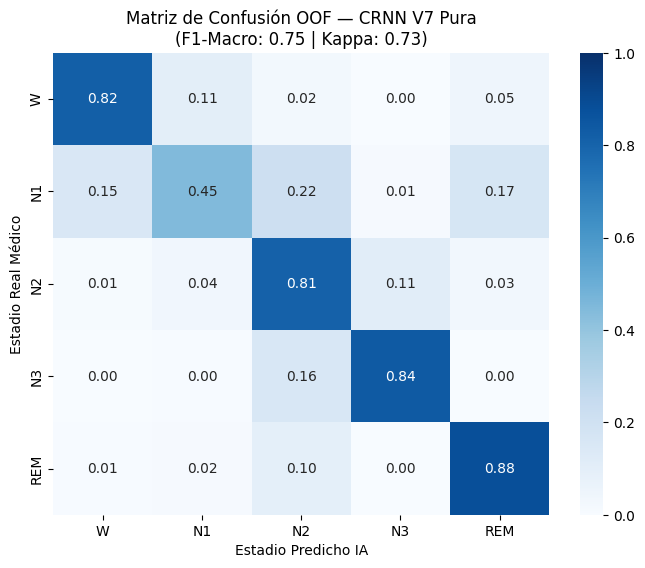

In [ ]:
cm_oof = confusion_matrix(y_true_univ, y_pred_oof_crnn, normalize='true')

plt.figure(figsize=(8, 6))
sns.heatmap(cm_oof, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS, vmin=0, vmax=1)
plt.title(f"Matriz de Confusión OOF — CRNN V7 Pura\n(F1-Macro: {f1_oof_crnn:.2f} | Kappa: {kappa_oof_crnn:.2f})")
plt.ylabel("Estadio Real Médico")
plt.xlabel("Estadio Predicho IA")
plt.show()

## 6. Consolidación del Extractor CRNN Maestro Universal (`modelo_crnn_universal_v7.keras`)

Una vez validada la arquitectura mediante el esquema *Out-Of-Fold*, se entrena el artefacto neuronal definitivo utilizando el 100% de la cohorte de entrenamiento universal (84 noches combinadas) bajo un programador de tasa de aprendizaje determinista (`LearningRateScheduler`). Este archivo `.keras` se exporta como el extractor de características de producción para cuando ingresen nuevos pacientes al sistema.

🚀 ENTRENANDO EXTRACTOR CRNN MAESTRO ÓPTIMO (100% COHORTE TRAIN)...
Epoch 1/20
671/671 ━━━━━━━━━━━━━━━━━━━━ 387s 533ms/step - accuracy: 0.7951 - loss: 0.3014 - learning_rate: 0.0010
Epoch 2/20
671/671 ━━━━━━━━━━━━━━━━━━━━ 358s 533ms/step - accuracy: 0.8288 - loss: 0.2165 - learning_rate: 0.0010
Epoch 3/20
671/671 ━━━━━━━━━━━━━━━━━━━━ 358s 533ms/step - accuracy: 0.8420 - loss: 0.1916 - learning_rate: 0.0010
Epoch 4/20
671/671 ━━━━━━━━━━━━━━━━━━━━ 358s 533ms/step - accuracy: 0.8496 - loss: 0.1767 - learning_rate: 0.0010
Epoch 5/20
671/671 ━━━━━━━━━━━━━━━━━━━━ 358s 533ms/step - accuracy: 0.8561 - loss: 0.1631 - learning_rate: 0.0010
Epoch 6/20
671/671 ━━━━━━━━━━━━━━━━━━━━ 358s 534ms/step - accuracy: 0.8646 - loss: 0.1505 - learning_rate: 0.0010
Epoch 7/20
671/671 ━━━━━━━━━━━━━━━━━━━━ 358s 533ms/step - accuracy: 0.8762 - loss: 0.1332 - learning_rate: 5.0000e-04
Epoch 8/20
671/671 ━━━━━━━━━━━━━━━━━━━━ 358s 533ms/step - accuracy: 0.8794 - loss: 0.1287 - learning_rate: 5.0000e-04
Epoch 9/20
67

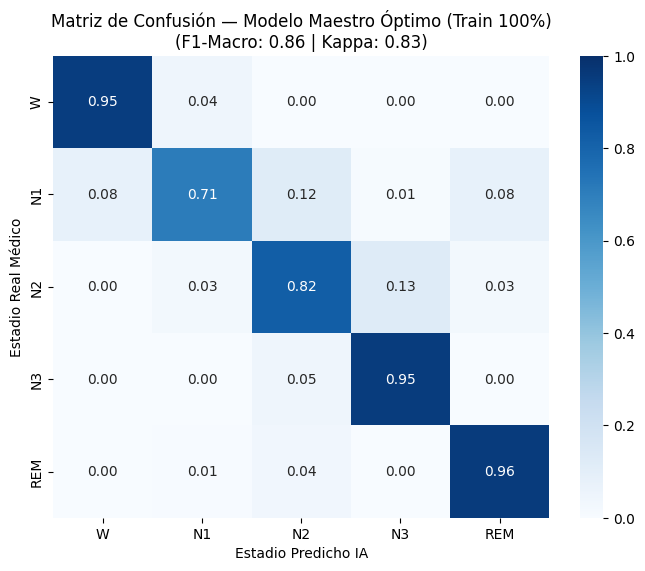

In [ ]:
# =================================================================
# SECCIÓN 6: ENTRENAMIENTO DEL MAESTRO Y EVALUACIÓN (TRAIN 100%)
# =================================================================
from tensorflow.keras.callbacks import LearningRateScheduler
from tensorflow.keras.models import Model

print("🚀 ENTRENANDO EXTRACTOR CRNN MAESTRO ÓPTIMO (100% COHORTE TRAIN)...")

def lr_schedule_v7(epoch, lr):
    if epoch < 6:
        return 0.0010
    elif epoch < 12:
        return 0.0005
    elif epoch < 16:
        return 0.00025
    else:
        return 0.000125

tf.keras.backend.clear_session()
# ⚠️ Aseguramos instanciar con los parámetros ganadores (Gamma=1.5 está en la función base)
modelo_maestro_v7 = create_crnn_universal_v7(seq_len=SEQ_LEN, num_classes=len(ETAPAS_VALIDAS), lr=LEARNING_RATE)

registro_ids_univ = meta_univ["registro_id"].to_numpy()
indices_totales = np.arange(len(X_univ))
ds_full_univ = MultimodalDataGenerator(indices_totales, X_univ, y_univ, registro_ids_univ, SEQ_LEN, BATCH_SIZE, shuffle=True)

clases_unicas = np.unique(y_true_univ)
pesos_full = compute_class_weight('balanced', classes=clases_unicas, y=y_true_univ)
dicc_pesos_full = {int(c): float(np.sqrt(p)) for c, p in zip(clases_unicas, pesos_full)}

modelo_maestro_v7.fit(
    ds_full_univ,
    epochs=EPOCHS_MAESTRO,
    class_weight=dicc_pesos_full,
    callbacks=[LearningRateScheduler(lr_schedule_v7)],
    verbose=1
)

# ⚠️ NUEVO NOMBRE DE ARCHIVO
ruta_crnn_optima = BASE_TELEMETRY / "modelo_crnn_maestro_optimo_v7.keras"
modelo_maestro_v7.save(ruta_crnn_optima)
print(f"\n✅ EXTRACTOR CRNN MAESTRO ÓPTIMO guardado en: {ruta_crnn_optima}")

# --- EVALUACIÓN Y MÉTRICAS DEL MODELO MAESTRO EN TODO EL TRAIN ---
print("\n📊 Creando generador en modo secuencial (shuffle=False) para evaluación...")
ds_eval_univ = MultimodalDataGenerator(
    indices_totales, X_univ, y_univ, registro_ids_univ, SEQ_LEN, BATCH_SIZE, shuffle=False
)

print("🔍 Ejecutando predicción ordenada sobre el 100% de los datos de entrenamiento...")
proba_maestro = modelo_maestro_v7.predict(ds_eval_univ, verbose=1)
y_pred_maestro = np.argmax(proba_maestro, axis=1)

acc_maestro   = accuracy_score(y_true_univ, y_pred_maestro)
f1_maestro    = f1_score(y_true_univ, y_pred_maestro, average='macro')
kappa_maestro = cohen_kappa_score(y_true_univ, y_pred_maestro)

print("\n" + "="*65)
print("🎯 RENDIMIENTO GLOBAL — MODELO MAESTRO CRNN V7 ÓPTIMO (TRAIN 100%)")
print("="*65)
print(f"Accuracy Global:           {acc_maestro:.4f}")
print(f"Índice Kappa de Cohen:     {kappa_maestro:.4f}")
print(f"F1-Score Macro:            {f1_maestro:.4f}")
print("="*65)

cm_maestro = confusion_matrix(y_true_univ, y_pred_maestro, normalize='true')
plt.figure(figsize=(8, 6))
sns.heatmap(cm_maestro, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS, vmin=0, vmax=1)
plt.title(f"Matriz de Confusión — Modelo Maestro Óptimo (Train 100%)\n(F1-Macro: {f1_maestro:.2f} | Kappa: {kappa_maestro:.2f})")
plt.ylabel("Estadio Real Médico")
plt.xlabel("Estadio Predicho IA")
plt.show()

## 7. Optimización Bayesiana de Hiperparámetros con Optuna y Registro en MLflow

Con el espacio latente *Out-Of-Fold* (`X_oof_embeddings` de 64 dimensiones) generado, se instancia un estudio de optimización bayesiana mediante el algoritmo **TPE (*Tree-structured Parzen Estimator*) de Optuna**:
* **Objetivo Matemático:** Maximizar directamente el **F1-Score Macro** promedio evaluado mediante un `GroupKFold(n_splits=5)` interno agrupado por `sujeto_id`.
* **Candados Anti-Memorización (Regularización Estricta):** Se restringe la profundidad máxima de los árboles (`max_depth` $\in [3, 7]$), se exige un mínimo elevado de épocas por hoja (`min_child_samples` $\in [60, 250]$) para impedir que el árbol aísle el voltaje basal de un sujeto específico, y se aplican penalizaciones $L_1$ (`reg_alpha`), $L_2$ (`reg_lambda`) y muestreo estocástico de características (`colsample_bytree`).
7.2 Código Python (Celda 7)

In [ ]:
# =========================================================
# SECCIÓN 7: EXTRACCIÓN MAESTRA Y OPTUNA ALINEADO
# =========================================================
import lightgbm as lgb
import optuna

print("🧠 1. Extrayendo el Espacio Latente del Modelo Maestro Óptimo...")

extractor_maestro_train = Model(
    inputs=modelo_maestro_v7.inputs,
    outputs=modelo_maestro_v7.get_layer('embeddings_latentes_64d').output
)

X_tabular_univ_maestro = extractor_maestro_train.predict(ds_eval_univ, verbose=1)
X_tabular_univ_maestro = np.asarray(X_tabular_univ_maestro, dtype=np.float32)

print("\n🌲 2. INICIANDO OPTIMIZACIÓN BAYESIANA DE LIGHTGBM...")

grupos_univ = meta_univ["sujeto_id"].to_numpy()
gkf_optuna = GroupKFold(n_splits=5)

def objective_lgbm_maestro(trial):
    params = {
        'objective': 'multiclass',
        'num_class': len(ETAPAS_VALIDAS),
        'n_estimators': trial.suggest_int('n_estimators', 200, 600, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.015, 0.08, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 7),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'min_child_samples': trial.suggest_int('min_child_samples', 60, 250, step=10),
        'subsample': trial.suggest_float('subsample', 0.6, 0.95),
        'subsample_freq': 1,
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 0.85),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-2, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
        'class_weight': 'balanced',
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }

    f1_scores = []
    for tr_idx, val_idx in gkf_optuna.split(X_tabular_univ_maestro, y_true_univ, groups=grupos_univ):
        X_tr, y_tr = X_tabular_univ_maestro[tr_idx], y_true_univ[tr_idx]
        X_va, y_va = X_tabular_univ_maestro[val_idx], y_true_univ[val_idx]

        clf = lgb.LGBMClassifier(**params)
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_va)
        f1_scores.append(f1_score(y_va, preds, average='macro'))

    return float(np.mean(f1_scores))

study = optuna.create_study(direction='maximize', study_name='LightGBM_Maestro_Optuna')
study.optimize(objective_lgbm_maestro, n_trials=30, show_progress_bar=True)

print("\n" + "="*65)
print("🏆 MEJORES HIPERPARÁMETROS ENCONTRADOS POR OPTUNA")
print("="*65)
print(f"Mejor F1-Score Macro Interno: {study.best_value:.4f}")

mejores_params = study.best_params.copy()
mejores_params.update({
    'objective': 'multiclass',
    'num_class': len(ETAPAS_VALIDAS),
    'class_weight': 'balanced',
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
})

print("\nEntrenando Motor LightGBM Universal Óptimo...")
clf_lgbm_optuna = lgb.LGBMClassifier(**mejores_params)
clf_lgbm_optuna.fit(X_tabular_univ_maestro, y_true_univ)

# ⚠️ NUEVO NOMBRE DE ARCHIVO
ruta_lgbm_optimo = BASE_TELEMETRY / "motor_lightgbm_optimo_v7.pkl"
joblib.dump(clf_lgbm_optuna, ruta_lgbm_optimo)
print(f"✅ Motor LightGBM Óptimo guardado en: {ruta_lgbm_optimo}")

try:
    ruta_mlflow = BASE_TELEMETRY / "mlruns"
    mlflow.set_tracking_uri(f"file://{ruta_mlflow}")
    mlflow.set_experiment("Optimizacion_Hiperparametros_CRNN")

    with mlflow.start_run(run_name="Ensamble_LGBM_Optimo_Gamma1.5"):
        mlflow.log_params(mejores_params)
        mlflow.log_metric("lgbm_maestro_f1_macro_cv", study.best_value)
    print("✅ Métricas del Ensamble registradas en MLflow.")
except Exception as e:
    print(f"⚠️ Aviso MLflow: {e}")

🧠 1. Extrayendo el Espacio Latente del Modelo Maestro Óptimo...
671/671 ━━━━━━━━━━━━━━━━━━━━ 111s 160ms/step

🌲 2. INICIANDO OPTIMIZACIÓN BAYESIANA DE LIGHTGBM...


  0%|          | 0/30 [00:00<?, ?it/s]


🏆 MEJORES HIPERPARÁMETROS ENCONTRADOS POR OPTUNA
Mejor F1-Score Macro Interno: 0.8756

Entrenando Motor LightGBM Universal Óptimo...
✅ Motor LightGBM Óptimo guardado en: /content/drive/MyDrive/Bimestre 7/Proyectos/sleep-telemetry/motor_lightgbm_optimo_v7.pkl
✅ Métricas del Ensamble registradas en MLflow.


## 8. Prueba de Fuego Definitiva: Evaluación en la Bóveda *Hold-Out* (20 Pacientes Inéditos)

Se abre la bóveda de prueba (`registros_cassette[40:60]`, correspondiente a 20 noches de pacientes jamás vistos ni por la red neuronal CRNN V7 ni por el estudio de Optuna) y se realiza la evaluación comparativa en dos fases:
* **Fase A (Matriz Azul):** Inferencia directa mediante la capa `Softmax` de la nueva red **CRNN Universal V7 (con *Data Augmentation*)**.
* **Fase B (Matriz Verde):** Extracción del espacio latente de 64 dimensiones e inferencia mediante el **Ensamble Universal LightGBM optimizado con Optuna**.

🔓 ABRIENDO BÓVEDA HOLD-OUT: Evaluando 20 noches inéditas de Sleep-Cassette...

-----------------------------------------------------------------
🧠 FASE A: INFERENCIA DIRECTA CON CRNN ÓPTIMA PURA
-----------------------------------------------------------------
190/190 ━━━━━━━━━━━━━━━━━━━━ 36s 173ms/step

🎯 REPORTE FASE A — CRNN ÓPTIMA PURA (Acc: 0.7600 | F1: 0.6928 | Kappa: 0.6736)
              precision    recall  f1-score   support

           W       0.80      0.94      0.86      7435
          N1       0.53      0.33      0.40      2516
          N2       0.83      0.70      0.76      9125
          N3       0.47      0.89      0.61      1568
         REM       0.86      0.79      0.82      3624

    accuracy                           0.76     24268
   macro avg       0.70      0.73      0.69     24268
weighted avg       0.77      0.76      0.75     24268


-----------------------------------------------------------------
🌲 FASE B: INFERENCIA CON ENSAMBLE ÓPTIMO (LIGHTGBM)
-------

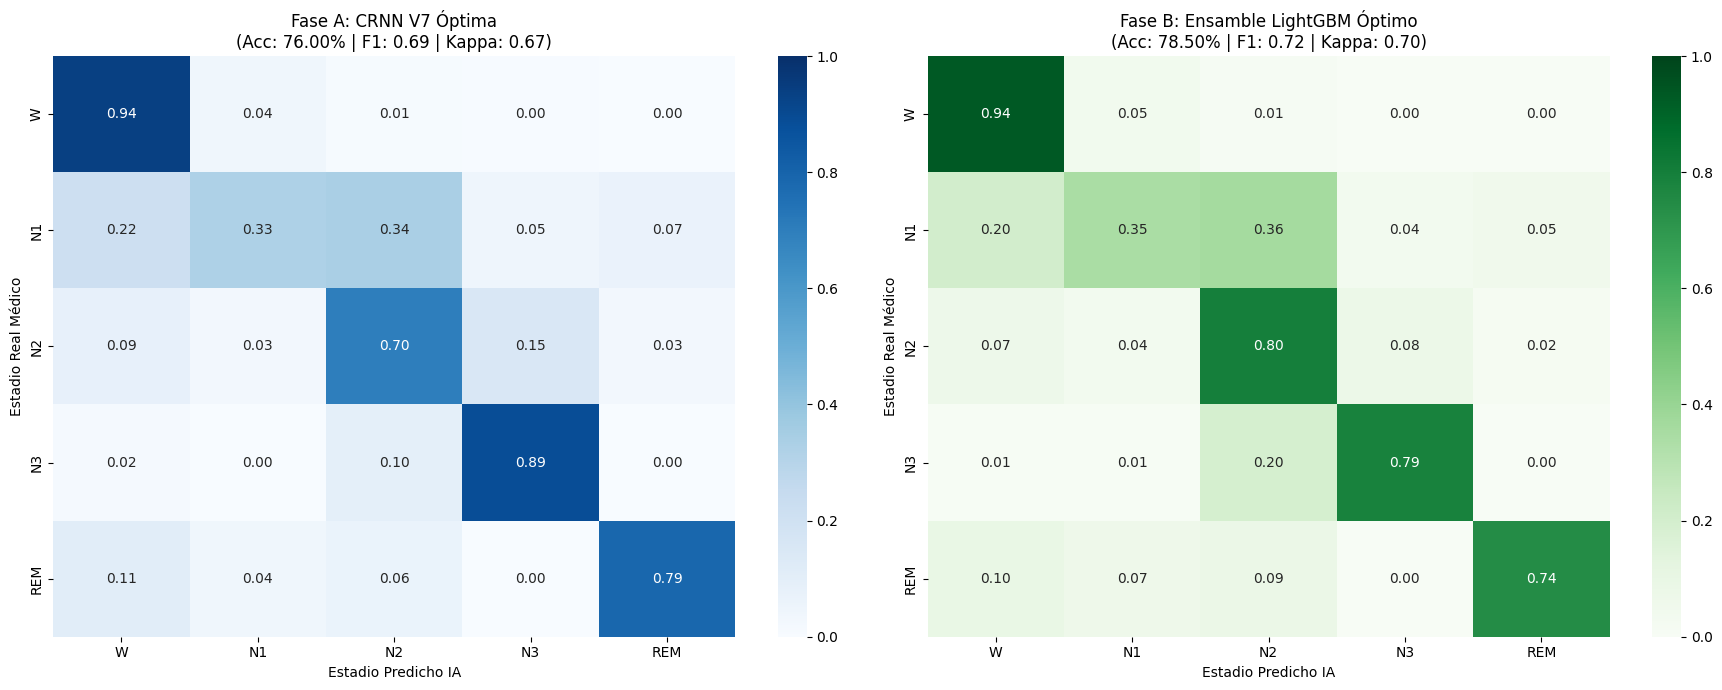

In [ ]:
# =====================================================================
# SECCIÓN 8: EVALUACIÓN FINAL EN BÓVEDA HOLD-OUT (20 PACIENTES NUEVOS)
# =====================================================================
from tensorflow.keras.models import load_model

print("🔓 ABRIENDO BÓVEDA HOLD-OUT: Evaluando 20 noches inéditas de Sleep-Cassette...")
X_test_holdout, y_test_holdout, meta_test_holdout = construir_dataset_cnn(registros_holdout_cas)

reg_ids_test = meta_test_holdout["registro_id"].to_numpy()
indices_test = np.arange(len(X_test_holdout))
ds_test_holdout = MultimodalDataGenerator(
    indices_test, X_test_holdout, y_test_holdout, reg_ids_test, SEQ_LEN, BATCH_SIZE, shuffle=False
)

y_true_holdout = np.argmax(y_test_holdout, axis=1)

# Cargar Extractor Maestro Óptimo
modelo_crnn_eval = load_model(
    BASE_TELEMETRY / "modelo_crnn_maestro_optimo_v7.keras",
    custom_objects={'loss': categorical_focal_loss(gamma=1.5)}
)

print("\n" + "-"*65)
print("🧠 FASE A: INFERENCIA DIRECTA CON CRNN ÓPTIMA PURA")
print("-" * 65)
proba_crnn_holdout = modelo_crnn_eval.predict(ds_test_holdout, verbose=1)
y_pred_crnn_holdout = np.argmax(proba_crnn_holdout, axis=1)

acc_fase_a   = accuracy_score(y_true_holdout, y_pred_crnn_holdout)
f1_fase_a    = f1_score(y_true_holdout, y_pred_crnn_holdout, average='macro')
kappa_fase_a = cohen_kappa_score(y_true_holdout, y_pred_crnn_holdout)

print(f"\n🎯 REPORTE FASE A — CRNN ÓPTIMA PURA (Acc: {acc_fase_a:.4f} | F1: {f1_fase_a:.4f} | Kappa: {kappa_fase_a:.4f})")
print(classification_report(y_true_holdout, y_pred_crnn_holdout, target_names=ETAPAS_VALIDAS))

print("\n" + "-"*65)
print("🌲 FASE B: INFERENCIA CON ENSAMBLE ÓPTIMO (LIGHTGBM)")
print("-" * 65)
extractor_holdout = Model(
    inputs=modelo_crnn_eval.inputs,
    outputs=modelo_crnn_eval.get_layer('embeddings_latentes_64d').output
)

print("Extrayendo embeddings 64D de los pacientes Hold-Out...")
X_tabular_holdout = np.asarray(extractor_holdout.predict(ds_test_holdout, verbose=1), dtype=np.float32)
y_pred_lgbm_holdout = clf_lgbm_optuna.predict(X_tabular_holdout)

acc_fase_b   = accuracy_score(y_true_holdout, y_pred_lgbm_holdout)
f1_fase_b    = f1_score(y_true_holdout, y_pred_lgbm_holdout, average='macro')
kappa_fase_b = cohen_kappa_score(y_true_holdout, y_pred_lgbm_holdout)

print(f"\n🎯 REPORTE FASE B — ENSAMBLE LIGHTGBM (Acc: {acc_fase_b:.4f} | F1: {f1_fase_b:.4f} | Kappa: {kappa_fase_b:.4f})")
print(classification_report(y_true_holdout, y_pred_lgbm_holdout, target_names=ETAPAS_VALIDAS))

# --- GRÁFICAS COMPARATIVAS ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

cm_a = confusion_matrix(y_true_holdout, y_pred_crnn_holdout, normalize='true')
sns.heatmap(cm_a, annot=True, fmt=".2f", cmap="Blues", ax=axes[0],
            xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS, vmin=0, vmax=1)
axes[0].set_title(f"Fase A: CRNN V7 Óptima\n(Acc: {acc_fase_a:.2%} | F1: {f1_fase_a:.2f} | Kappa: {kappa_fase_a:.2f})")
axes[0].set_ylabel("Estadio Real Médico")
axes[0].set_xlabel("Estadio Predicho IA")

cm_b = confusion_matrix(y_true_holdout, y_pred_lgbm_holdout, normalize='true')
sns.heatmap(cm_b, annot=True, fmt=".2f", cmap="Greens", ax=axes[1],
            xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS, vmin=0, vmax=1)
axes[1].set_title(f"Fase B: Ensamble LightGBM Óptimo\n(Acc: {acc_fase_b:.2%} | F1: {f1_fase_b:.2f} | Kappa: {kappa_fase_b:.2f})")
axes[1].set_ylabel("Estadio Real Médico")
axes[1].set_xlabel("Estadio Predicho IA")

plt.tight_layout()
plt.show()